In [22]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import warnings; warnings.filterwarnings("ignore")

proc = "/nobackup/proj/comet_smmnfst/processed/"
adata = sc.read_h5ad(proc + "region1_niches.h5ad")

In [23]:
mac = adata[adata.obs["cell_type"].isin(["Macrophage"])].copy()
print(mac.n_obs, "myeloid cells")

1311 myeloid cells


In [24]:
sc.pp.highly_variable_genes(mac, n_top_genes=1000)
sc.pp.pca(mac, n_comps=20, mask_var="highly_variable")
sc.pp.neighbors(mac, n_neighbors=15)
sc.tl.umap(mac)
sc.tl.leiden(mac, resolution=1.0, key_added="mac_sub", flavor="igraph", n_iterations=2)
mac.obs["mac_sub"].value_counts()

mac_sub
0     233
6     212
3     158
7     122
2     117
4     112
9      81
5      68
10     67
8      64
1      42
11     35
Name: count, dtype: int64

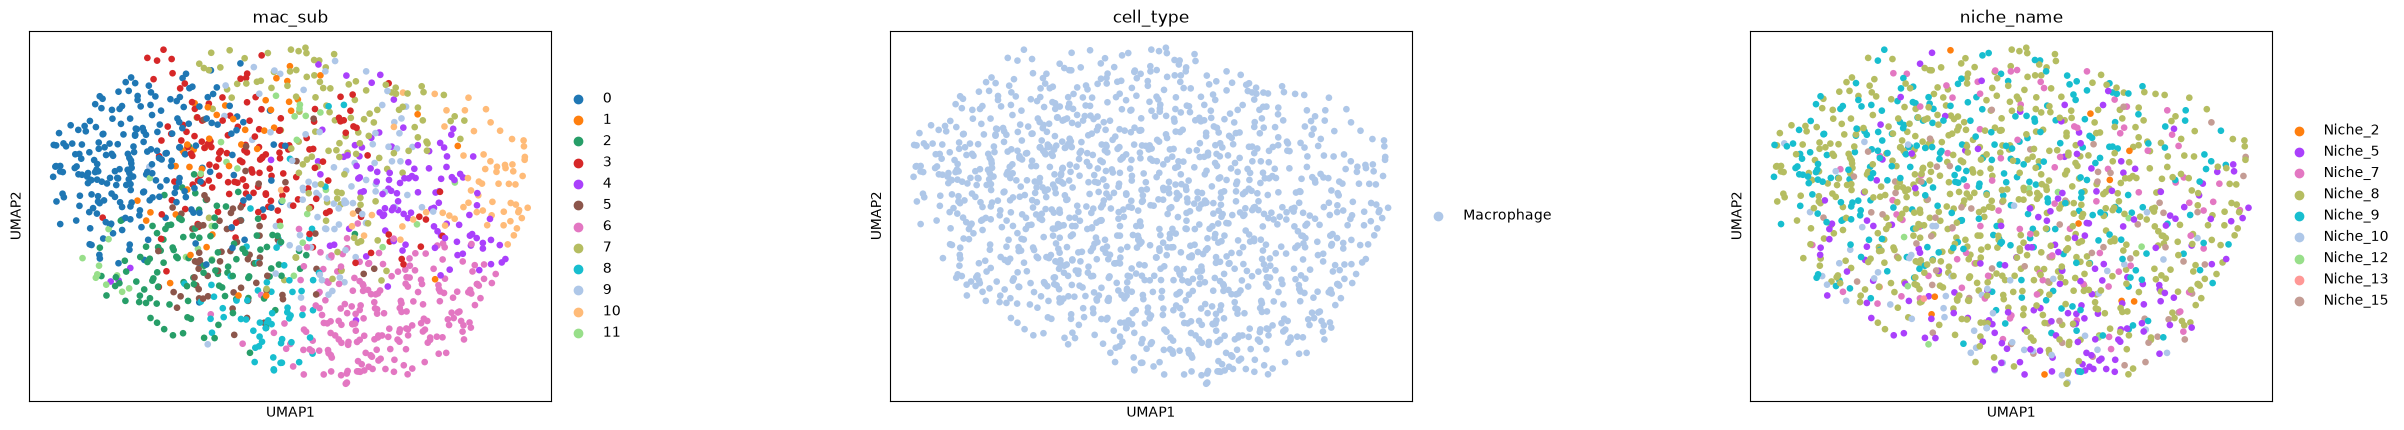

In [25]:
sc.pl.umap(mac, color=["mac_sub", "cell_type", "niche_name"], ncols=3, wspace=0.5)

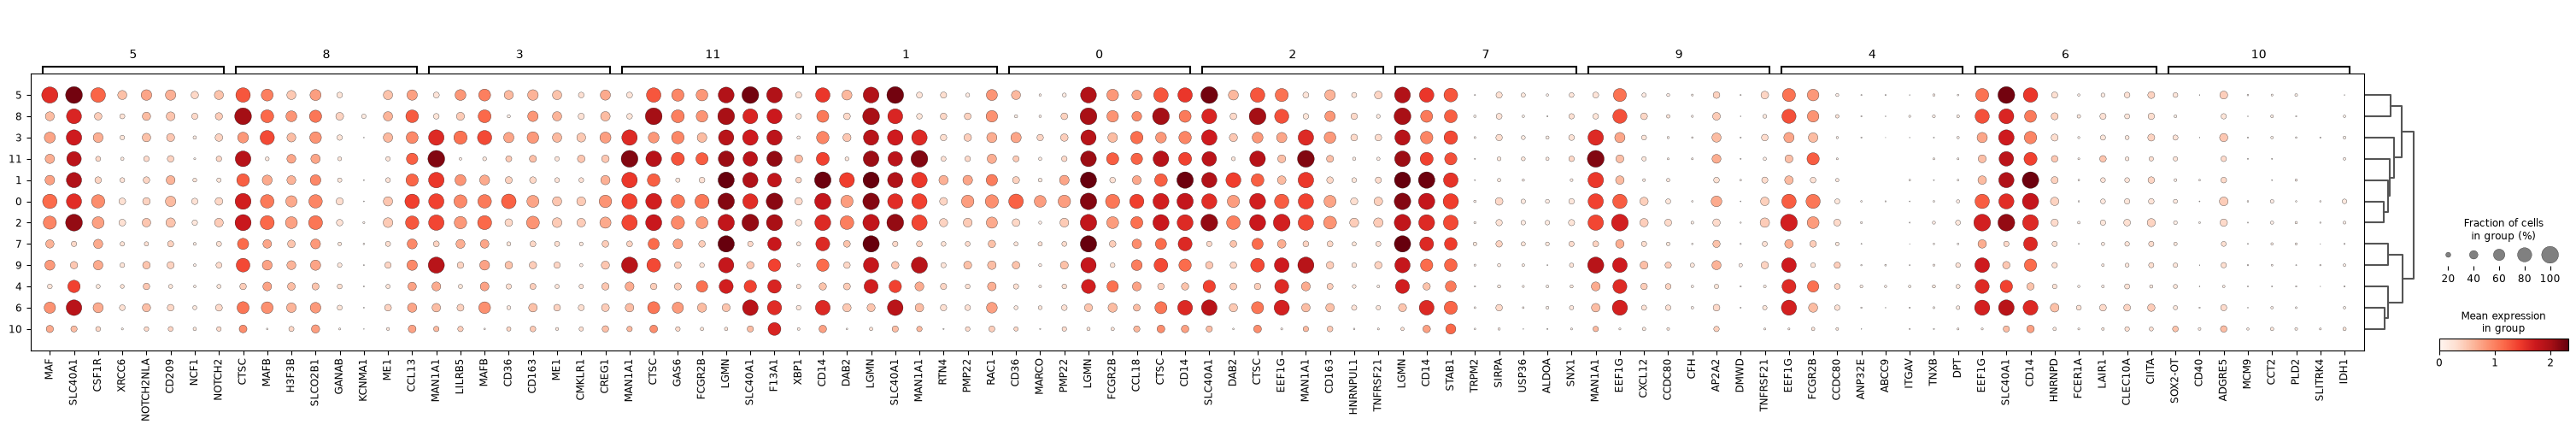

cell_type,Macrophage
mac_sub,
0,233
1,42
2,117
3,158
4,112
5,68
6,212
7,122
8,64


In [26]:
sc.tl.rank_genes_groups(mac, groupby="mac_sub", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(mac, n_genes=8)
pd.crosstab(mac.obs["mac_sub"], mac.obs["cell_type"])

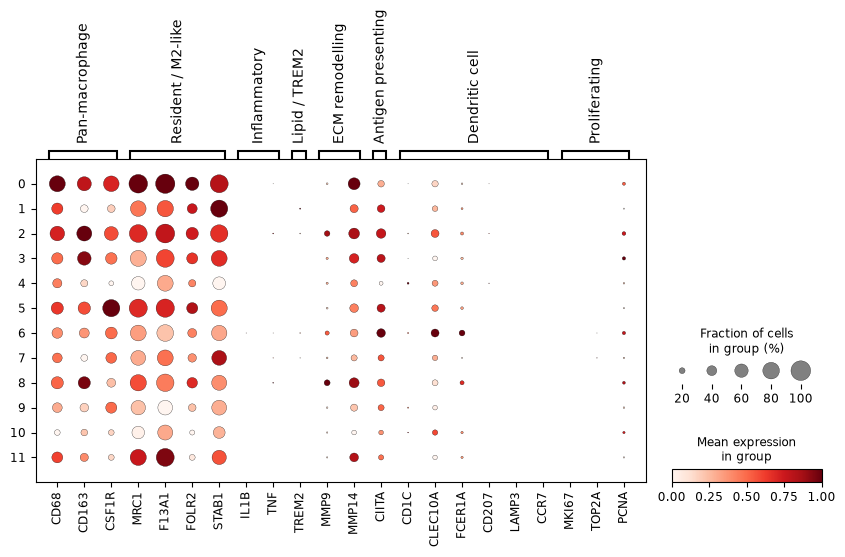

In [27]:
mac_markers = {
    "Pan-macrophage":     ["CD68", "CD163", "CSF1R", "C1QA", "C1QB"],
    "Resident / M2-like": ["MRC1", "F13A1", "LYVE1", "FOLR2", "STAB1"],
    "Inflammatory":       ["IL1B", "TNF", "CXCL8", "CCL3", "S100A8"],
    "Lipid / TREM2":      ["TREM2", "APOE", "GPNMB", "SPP1", "LGALS3"],
    "ECM remodelling":    ["MMP9", "MMP14", "FN1", "TGFBI", "VCAN", "CTSB", "CTSD"],
    "Antigen presenting": ["HLA-DRA", "HLA-DQA1", "CD74", "CIITA"],
    "Dendritic cell":     ["CD1C", "CLEC10A", "FCER1A", "CD207", "LAMP3", "CCR7"],
    "Proliferating":      ["MKI67", "TOP2A", "PCNA"],
}
mac_markers = {k: [g for g in v if g in mac.var_names] for k, v in mac_markers.items()}
sc.pl.dotplot(mac, mac_markers, groupby="mac_sub", standard_scale="var")

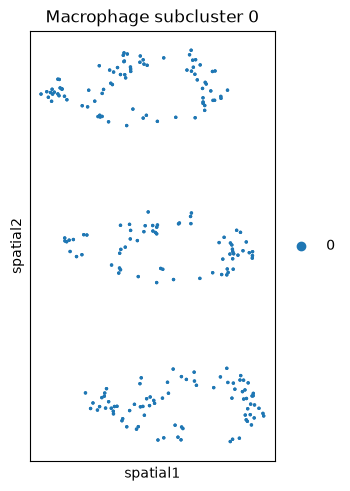

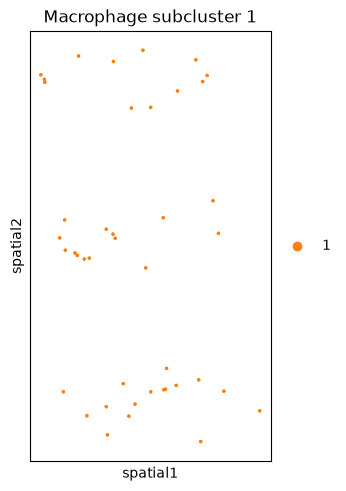

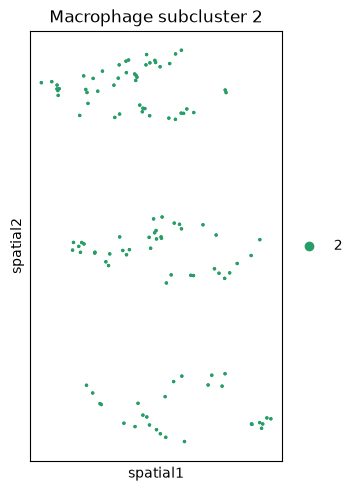

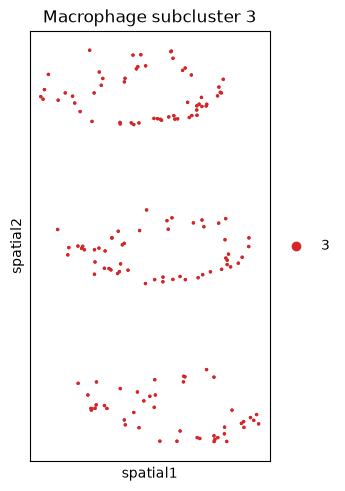

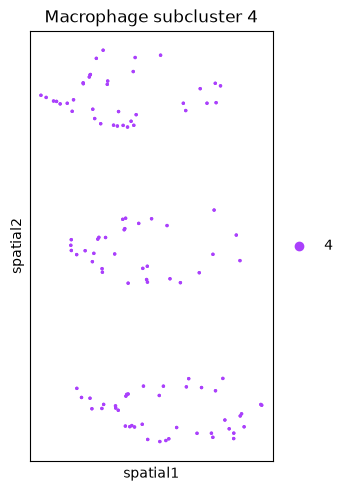

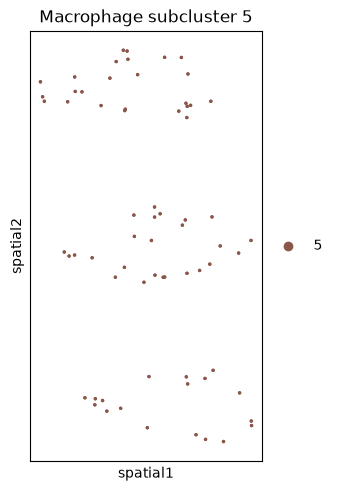

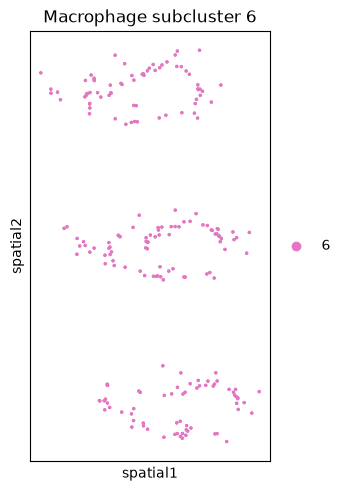

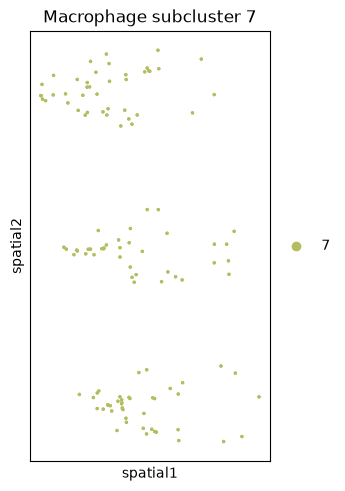

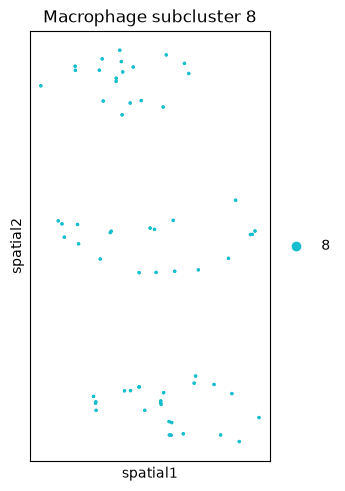

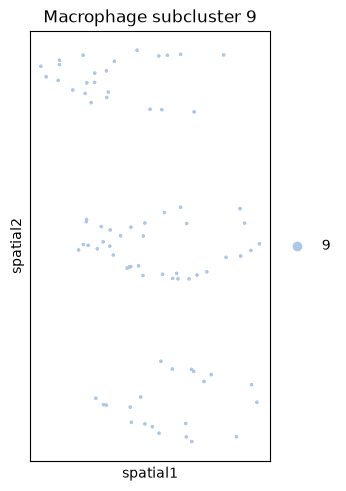

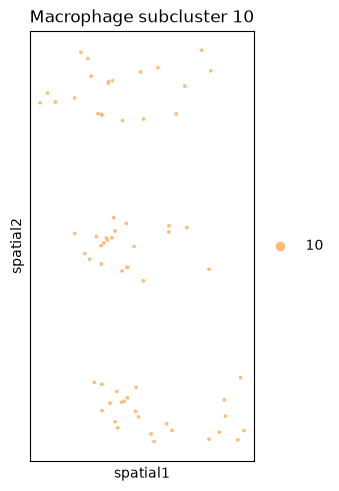

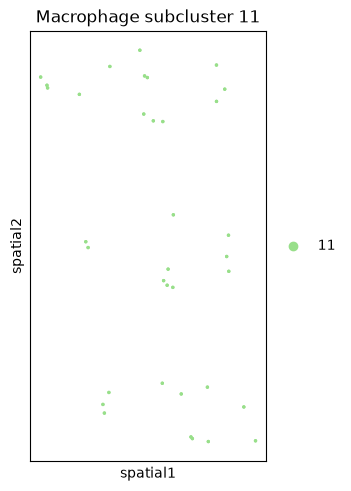

In [28]:
for c in mac.obs["mac_sub"].cat.categories:
    sq.pl.spatial_scatter(mac, color="mac_sub", groups=[c], shape=None, size=8, title=f"Macrophage subcluster {c}")

In [29]:
mac_names = {
    "0": "Subcluster_0",
    "1": "Subcluster_1",
    "2": "Subcluster_2",
}
missing = [k for k, v in mac_names.items() if v == ""]
assert not missing, f"still unnamed: {missing}"
mac.obs["mac_state"] = mac.obs["mac_sub"].map(mac_names).astype("category")

In [30]:
adata.obs["cell_type_fine"] = adata.obs["cell_type"].astype(str)
adata.obs.loc[mac.obs_names, "cell_type_fine"] = mac.obs["mac_state"].astype(str)
adata.obs["cell_type_fine"] = adata.obs["cell_type_fine"].astype("category")
adata.obs["cell_type_fine"].value_counts()

cell_type_fine
Spinous keratinocyte                 4338
Basal keratinocyte                   3727
Fibroblast reticular (PI16+)         3263
Basal-to-spinous keratinocyte        3128
Endothelial blood                    2194
Schwann / nerve                      1897
Hair follicle ORS basal (SOX9+)      1751
Spinous keratinocyte upper           1558
T cell                               1516
Upper spinous / early granular       1309
Granular / cornified keratinocyte    1208
Basal keratinocyte proliferating      918
Fibroblast papillary (FAP+ DPP4+)     907
Dendritic cell (cDC2)                 657
Melanocyte                            593
Endothelial lymphatic                 399
Langerhans cell                       397
Mast cell                             241
Subcluster_0                          233
Subcluster_2                          117
Subcluster_1                           42
Name: count, dtype: int64

In [31]:
adata.write(proc + "region1_macrophages.h5ad")
mac.write(proc + "region1_myeloid_subset.h5ad")